# 04 · CNNs from scratch: a baseline and an improved version

**Goal:** train two small CNNs of our own on the training images and see what overfitting looks like and how much regularisation fixes it.

**Inputs:** the split from notebook 02 and the NEU images. Pipeline and augmentation as built in notebook 03.

**Outputs:**
- `outputs/models/m1_baseline.keras`, `m2_improved.keras`
- `outputs/results/val_results_scratch.csv` and `history_<model>.csv` (loss and accuracy per epoch)
- figures `outputs/figures/model_01_m1_curves.png`, `model_02_m2_curves.png`

| ID | Model | Idea |
|---|---|---|
| M1 | Small CNN from scratch, no augmentation | The simplest CNN we can explain layer by layer. We expect it to overfit. |
| M2 | M1 + batch normalisation + augmentation | Shows how much regularisation helps on 210 images per class. |

Transfer learning with MobileNetV2 (M3) is in notebook 05. The test images are not touched here.

## Setup

In [1]:
import json
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow import keras

SEED = 42
keras.utils.set_random_seed(SEED)
ON_KAGGLE = Path("/kaggle/input").exists()

if ON_KAGGLE:
    PROJECT = Path("/kaggle/working")
    DATA_ROOT = next(Path("/kaggle/input").rglob("NEU-DET")).parent
    SPLIT_DIR = next(Path("/kaggle/input").rglob("train.csv")).parent
else:
    PROJECT = Path.cwd().parent
    DATA_ROOT = PROJECT / "data" / "raw"
    SPLIT_DIR = PROJECT / "data" / "splits"

FIG_DIR = PROJECT / "outputs" / "figures"
RES_DIR = PROJECT / "outputs" / "results"
MODEL_DIR = PROJECT / "outputs" / "models"
for folder in (FIG_DIR, RES_DIR, MODEL_DIR):
    folder.mkdir(parents=True, exist_ok=True)

CLASSES = ["crazing", "inclusion", "patches", "pitted_surface", "rolled-in_scale", "scratches"]
train_df = pd.read_csv(SPLIT_DIR / "train.csv")
val_df = pd.read_csv(SPLIT_DIR / "val.csv")
print("train", len(train_df), "| val", len(val_df))
print("TensorFlow", tf.__version__, "| GPUs:", tf.config.list_physical_devices("GPU"))

train 1260 | val 270
TensorFlow 2.20.0 | GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]


## Pipeline (same as notebook 03)

One change for speed: decoded images are cached in memory after the first epoch (`cache`), and the training set is reshuffled every epoch after that.

In [2]:
BATCH = 32
AUTOTUNE = tf.data.AUTOTUNE


def make_dataset(part, image_size, three_channels=False, shuffle=False):
    paths = [str(DATA_ROOT / p) for p in part["filepath"]]
    labels = [CLASSES.index(c) for c in part["label"]]
    ds = tf.data.Dataset.from_tensor_slices((paths, labels))

    def load(path, label):
        img = tf.io.decode_jpeg(tf.io.read_file(path), channels=1)
        img = tf.image.resize(img, (image_size, image_size))
        if three_channels:
            img = tf.image.grayscale_to_rgb(img)
            img = keras.applications.mobilenet_v2.preprocess_input(img)
        else:
            img = img / 255.0
        return img, label

    ds = ds.map(load, num_parallel_calls=AUTOTUNE).cache()
    if shuffle:
        ds = ds.shuffle(len(paths), seed=SEED, reshuffle_each_iteration=True)
    return ds.batch(BATCH).prefetch(AUTOTUNE)


def augmentation(value_range):
    return keras.Sequential([
        keras.layers.RandomFlip("horizontal_and_vertical", seed=SEED),
        keras.layers.RandomRotation(0.05, fill_mode="reflect", seed=SEED),
        keras.layers.RandomZoom(0.1, fill_mode="reflect", seed=SEED),
        keras.layers.RandomContrast(0.2, seed=SEED),
        keras.layers.RandomBrightness(0.2, value_range=value_range, seed=SEED),
    ], name="augmentation")


train_200 = make_dataset(train_df, 200, shuffle=True)
val_200 = make_dataset(val_df, 200)

I0000 00:00:1792297498.269728      21 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1792297498.273625      21 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


## Training setup shared by all models

- **Loss:** sparse categorical cross-entropy. It is small when the model gives high probability to the true class.
- **Optimiser:** Adam, which adapts the step size for each weight.
- **EarlyStopping:** stop when validation loss has not improved for 8 epochs, and go back to the best epoch's weights.
- **ReduceLROnPlateau:** halve the learning rate when validation loss stalls for 4 epochs.
- **ModelCheckpoint:** keep the file of the epoch with the lowest validation loss.

Our own CNNs get at most 100 epochs and an early-stopping patience of 12. With only 270 validation images the validation curve is jumpy, and a short patience stops training before the learning-rate reductions have calmed it down. The numbers we keep for each model go into one table at the end.

In [3]:
results = []


def train(model, name, train_ds, val_ds, lr, epochs=50, patience=8):
    model.compile(optimizer=keras.optimizers.Adam(lr), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    callbacks = [
        keras.callbacks.EarlyStopping(monitor="val_loss", patience=patience, restore_best_weights=True),
        keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=4, min_lr=1e-7),
        keras.callbacks.ModelCheckpoint(MODEL_DIR / f"{name}.keras", monitor="val_loss", save_best_only=True),
    ]
    start = time.time()
    history = model.fit(train_ds, validation_data=val_ds, epochs=epochs, callbacks=callbacks, verbose=2)
    seconds = time.time() - start
    hist = pd.DataFrame(history.history)
    hist.index.name = "epoch"
    return hist, seconds


def record(model, name, hist, seconds, note=""):
    best = int(hist["val_loss"].idxmin())
    model.save(MODEL_DIR / f"{name}.keras")
    row = {
        "model": name,
        "params": int(model.count_params()),
        "epochs_trained": int(len(hist)),
        "best_epoch": best + 1,
        "val_accuracy": round(float(hist.loc[best, "val_accuracy"]), 4),
        "val_loss": round(float(hist.loc[best, "val_loss"]), 4),
        "train_accuracy_at_best": round(float(hist.loc[best, "accuracy"]), 4),
        "train_time_s": round(seconds, 1),
        "model_size_mb": round((MODEL_DIR / f"{name}.keras").stat().st_size / 1e6, 2),
        "note": note,
    }
    hist.to_csv(RES_DIR / f"history_{name}.csv")
    results.append(row)
    print(json.dumps(row, indent=2))
    return row


def plot_curves(hist, title, filename):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    epochs = np.arange(1, len(hist) + 1)
    for ax, metric, label in ((axes[0], "loss", "Loss (cross-entropy)"), (axes[1], "accuracy", "Accuracy")):
        ax.plot(epochs, hist[metric], label="train", color="#3b5b92")
        ax.plot(epochs, hist[f"val_{metric}"], label="validation", color="#d1495b")
        ax.set_xlabel("Epoch")
        ax.set_ylabel(label)
        ax.legend()
    best = int(hist["val_loss"].idxmin()) + 1
    for ax in axes:
        ax.axvline(best, color="grey", linestyle=":", linewidth=1)
    fig.suptitle(f"{title} (dotted line: best validation loss, epoch {best})", fontsize=12)
    fig.tight_layout()
    fig.savefig(FIG_DIR / filename, dpi=150)
    plt.show()

## M1 · Baseline CNN from scratch, no augmentation

Three convolution blocks. Each block has a 3 × 3 convolution (it slides small filters over the image and responds to edges and textures) followed by 2 × 2 max pooling (it halves the image size, keeping the strongest response). The filters grow from 32 to 64 to 128 as the image shrinks, so later layers see larger patterns. Global average pooling turns each of the 128 feature maps into one number, then a dense layer and a 6-way softmax give the class probabilities. Dropout switches off half of the dense units at random during training.

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 200, 200, 1)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 200, 200, 32)   │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 200, 200, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 100, 100, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 100, 100, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 100, 100, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 50, 50, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 50, 50, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 50, 50, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 25, 25, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 6)              │           774 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 109,958 (429.52 KB)

 Trainable params: 109,958 (429.52 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/100


I0000 00:00:1792297510.911226      66 device_compiler.h:196] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


40/40 - 16s - 403ms/step - accuracy: 0.1881 - loss: 1.7726 - val_accuracy: 0.1852 - val_loss: 1.7357 - learning_rate: 0.0010
Epoch 2/100
40/40 - 2s - 41ms/step - accuracy: 0.2683 - loss: 1.6439 - val_accuracy: 0.3778 - val_loss: 1.4341 - learning_rate: 0.0010
Epoch 3/100
40/40 - 2s - 41ms/step - accuracy: 0.5222 - loss: 1.1852 - val_accuracy: 0.6926 - val_loss: 0.8653 - learning_rate: 0.0010
Epoch 4/100
40/40 - 2s - 40ms/step - accuracy: 0.6278 - loss: 0.8993 - val_accuracy: 0.7630 - val_loss: 0.7299 - learning_rate: 0.0010
Epoch 5/100
40/40 - 2s - 40ms/step - accuracy: 0.7262 - loss: 0.7198 - val_accuracy: 0.7370 - val_loss: 0.5970 - learning_rate: 0.0010
Epoch 6/100
40/40 - 2s - 39ms/step - accuracy: 0.7246 - loss: 0.6993 - val_accuracy: 0.7074 - val_loss: 0.7153 - learning_rate: 0.0010
Epoch 7/100
40/40 - 2s - 41ms/step - accuracy: 0.7619 - loss: 0.6317 - val_accuracy: 0.8370 - val_loss: 0.4963 - learning_rate: 0.0010
Epoch 8/100
40/40 - 2s - 41ms/step - accuracy: 0.7865 - loss: 0.5

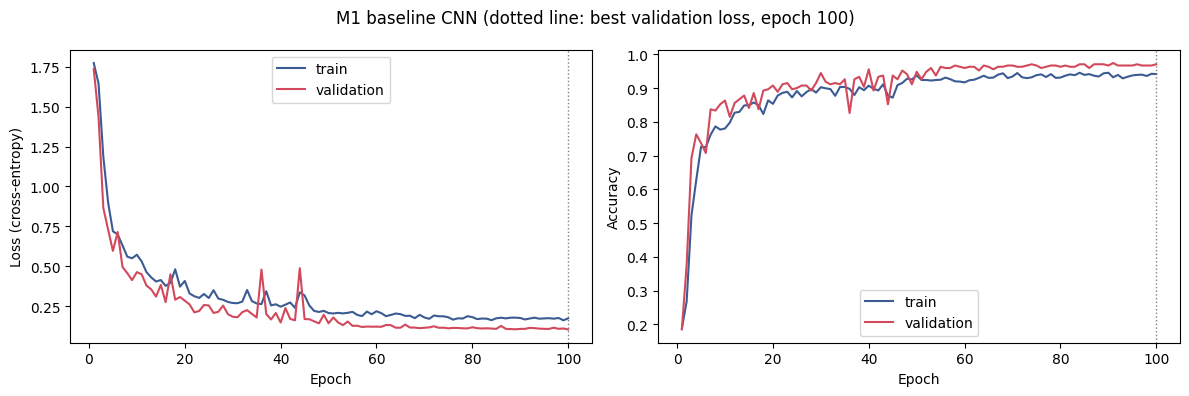

In [4]:
def baseline_cnn(augment=None, batch_norm=False):
    inputs = keras.Input((200, 200, 1))
    x = augment(inputs) if augment is not None else inputs
    for filters in (32, 64, 128):
        x = keras.layers.Conv2D(filters, 3, padding="same", use_bias=not batch_norm)(x)
        if batch_norm:
            x = keras.layers.BatchNormalization(momentum=0.9)(x)
        x = keras.layers.Activation("relu")(x)
        x = keras.layers.MaxPooling2D(2)(x)
    x = keras.layers.GlobalAveragePooling2D()(x)
    x = keras.layers.Dense(128, activation="relu")(x)
    x = keras.layers.Dropout(0.5)(x)
    outputs = keras.layers.Dense(len(CLASSES), activation="softmax")(x)
    return keras.Model(inputs, outputs)


m1 = baseline_cnn()
m1.summary()
hist_m1, sec_m1 = train(m1, "m1_baseline", train_200, val_200, lr=1e-3, epochs=100, patience=12)
record(m1, "m1_baseline", hist_m1, sec_m1, "3 conv blocks, no augmentation")
plot_curves(hist_m1, "M1 baseline CNN", "model_01_m1_curves.png")

## M2 · Same CNN + batch normalisation + augmentation

Two changes, both against overfitting:
- **Augmentation** (the layers from notebook 03) shows the network a new random variant of every image each epoch.
- **Batch normalisation** after each convolution rescales the activations of each batch, which makes training steadier and allows a faster learning rate.

At prediction time batch normalisation cannot use batch statistics, so it uses running averages collected during training. We set their momentum to 0.9 instead of the Keras default 0.99. With only 40 training batches per epoch, the default lets the running averages lag far behind the real values: in our first run M2 predicted the same class for every validation image (16.7 % accuracy, pure chance) because of this. See `LOG.md`.

Model: "functional_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 200, 200, 1)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augmentation (Sequential)       │ (None, 200, 200, 1)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 200, 200, 32)   │           288 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 200, 200, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 200, 200, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 100, 100, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 100, 100, 64)   │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 100, 100, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_4 (Activation)       │ (None, 100, 100, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 50, 50, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 50, 50, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 50, 50, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_5 (Activation)       │ (None, 50, 50, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 25, 25, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 6)              │           774 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 110,630 (432.15 KB)

 Trainable params: 110,182 (430.40 KB)

 Non-trainable params: 448 (1.75 KB)

Epoch 1/100
40/40 - 11s - 268ms/step - accuracy: 0.5079 - loss: 1.2895 - val_accuracy: 0.2667 - val_loss: 1.9743 - learning_rate: 0.0010
Epoch 2/100
40/40 - 4s - 94ms/step - accuracy: 0.6476 - loss: 0.9247 - val_accuracy: 0.4852 - val_loss: 1.3711 - learning_rate: 0.0010
Epoch 3/100
40/40 - 4s - 92ms/step - accuracy: 0.7032 - loss: 0.7945 - val_accuracy: 0.4704 - val_loss: 1.6668 - learning_rate: 0.0010
Epoch 4/100
40/40 - 4s - 93ms/step - accuracy: 0.7770 - loss: 0.6272 - val_accuracy: 0.5037 - val_loss: 2.4865 - learning_rate: 0.0010
Epoch 5/100
40/40 - 4s - 93ms/step - accuracy: 0.7929 - loss: 0.5630 - val_accuracy: 0.4222 - val_loss: 2.4772 - learning_rate: 0.0010
Epoch 6/100
40/40 - 4s - 93ms/step - accuracy: 0.8254 - loss: 0.5225 - val_accuracy: 0.6259 - val_loss: 1.5557 - learning_rate: 0.0010
Epoch 7/100
40/40 - 4s - 95ms/step - accuracy: 0.8532 - loss: 0.4415 - val_accuracy: 0.9000 - val_loss: 0.4081 - learning_rate: 5.0000e-04
Epoch 8/100
40/40 - 4s - 93ms/step - accuracy: 0.

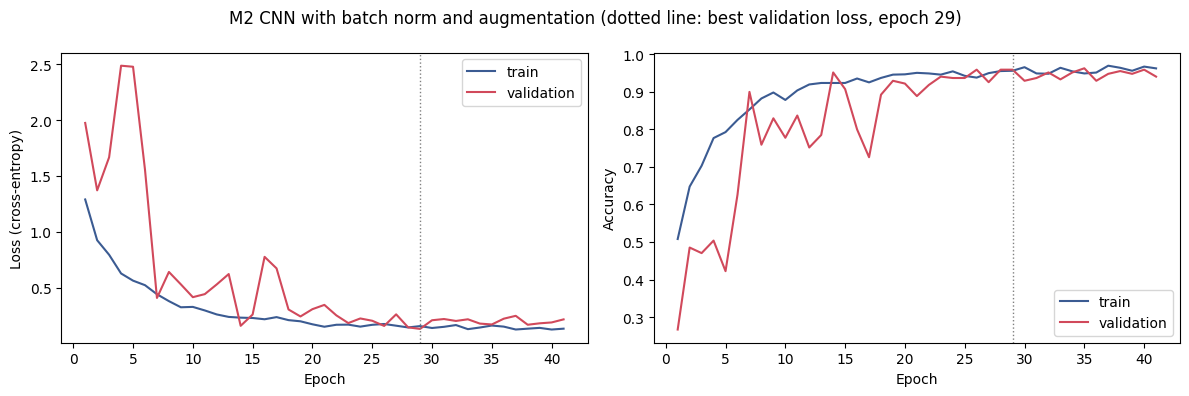

In [5]:
m2 = baseline_cnn(augment=augmentation((0.0, 1.0)), batch_norm=True)
m2.summary()
hist_m2, sec_m2 = train(m2, "m2_improved", train_200, val_200, lr=1e-3, epochs=100, patience=12)
record(m2, "m2_improved", hist_m2, sec_m2, "M1 + batch norm + augmentation")
plot_curves(hist_m2, "M2 CNN with batch norm and augmentation", "model_02_m2_curves.png")

## M1 vs M2 on the validation set

In [6]:
val_results = pd.DataFrame(results)
val_results.to_csv(RES_DIR / "val_results_scratch.csv", index=False)
val_results

,model,params,epochs_trained,best_epoch,val_accuracy,val_loss,train_accuracy_at_best,train_time_s,model_size_mb,note
0,m1_baseline,109958,100,100,0.9704,0.1056,0.9413,182.1,1.38,"3 conv blocks, no augmentation"
1,m2_improved,110630,41,29,0.9593,0.1310,0.9563,158.6,1.41,M1 + batch norm + augmentation


## What we found

- **M1, the plain CNN, reached 97.04 % validation accuracy** (validation loss 0.106). Its training accuracy, measured with dropout switched on, stayed below the validation accuracy in 91 of 100 epochs, so it was not memorising the training images. It was still improving slowly when the 100-epoch limit stopped it.
- **M2 reached 95.93 %**, three validation images fewer than M1. On this small and clean dataset, batch normalisation and augmentation did not beat a tiny CNN that already has dropout and global average pooling. M1 has only 109,958 parameters, so it has little room to memorise.
- **M2's validation curve is jumpy:** after epoch 10 its validation accuracy still moves between 72.6 % and 96.3 %. With 270 validation images, one image is 0.37 percentage points, so small differences between models are within this noise.